In [1]:
import pandas as pd 
import numpy as np
from mlxtend.plotting import plot_decision_regions

In [2]:
df = pd.DataFrame()

In [3]:
df['X1'] = [1,2,3,4,5,6,6,7,9,9]
df['X2'] = [5,3,6,8,1,9,5,8,9,2]
df['label'] = [1,1,0,1,0,1,0,1,0,0]

In [4]:
df

,X1,X2,label
0,1,5,1
1,2,3,1
2,3,6,0
3,4,8,1
4,5,1,0
5,6,9,1
6,6,5,0
7,7,8,1
8,9,9,0
9,9,2,0


In [5]:
import seaborn as sns

<Axes: xlabel='X1', ylabel='X2'>

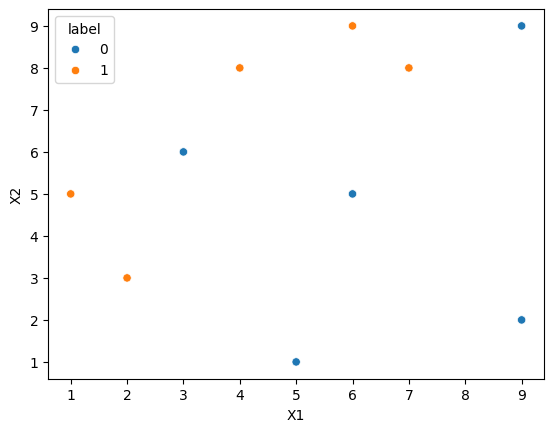

In [6]:
sns.scatterplot(x=df['X1'], y=df['X2'], hue=df['label'])

In [7]:
df['weights']=1/df.shape[0]

In [8]:
df

,X1,X2,label,weights
0,1,5,1,0.1
1,2,3,1,0.1
2,3,6,0,0.1
3,4,8,1,0.1
4,5,1,0,0.1
5,6,9,1,0.1
6,6,5,0,0.1
7,7,8,1,0.1
8,9,9,0,0.1
9,9,2,0,0.1


In [9]:
from sklearn.tree import DecisionTreeClassifier

In [10]:
dt1 = DecisionTreeClassifier(max_depth=1)

In [11]:
X = df.iloc[:,0:2].values
y = df.iloc[:,-2].values

In [12]:
dt1.fit(X,y)

DecisionTreeClassifier(max_depth=1)

In [13]:
from sklearn.tree import plot_tree

[Text(0.5, 0.75, 'x[0] <= 2.5\ngini = 0.5\nsamples = 10\nvalue = [5, 5]'),
 Text(0.25, 0.25, 'gini = 0.0\nsamples = 2\nvalue = [0, 2]'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.469\nsamples = 8\nvalue = [5, 3]'),
 Text(0.625, 0.5, '  False')]

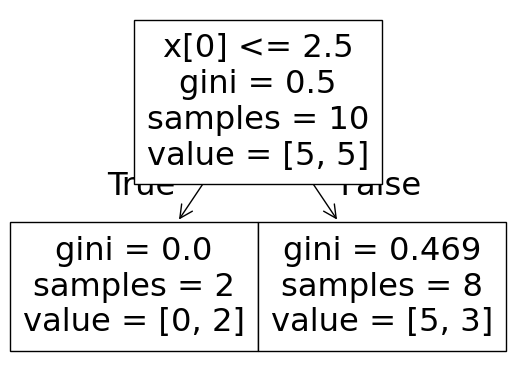

In [14]:
plot_tree(dt1)

<Axes: >

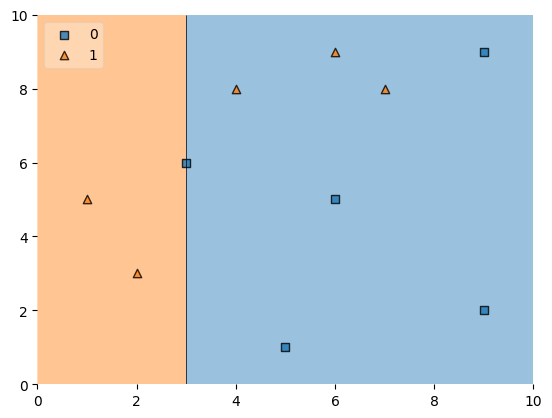

In [15]:
plot_decision_regions(X,y,clf=dt1, legend=2)

In [16]:
df['y_pred']=dt1.predict(X)

In [17]:
df

,X1,X2,label,weights,y_pred
0,1,5,1,0.1,1
1,2,3,1,0.1,1
2,3,6,0,0.1,0
3,4,8,1,0.1,0
4,5,1,0,0.1,0
5,6,9,1,0.1,0
6,6,5,0,0.1,0
7,7,8,1,0.1,0
8,9,9,0,0.1,0
9,9,2,0,0.1,0


In [50]:
def calculate_model_weight(error):
    return 0.5*np.log((1-error)/(error+0.0000001))

In [19]:
alpha1 = calculate_model_weight(0.3)

In [20]:
alpha1

0.42364893019360184

In [21]:
def update_row_weights(row, alpha=-0.4236):
    if row['label']==row['y_pred']:
        return row['weights']*np.exp(-alpha)
    else:
        return row['weights']*np.exp(alpha)

In [22]:
df['updated_weights']=df.apply(update_row_weights,axis=1)

In [23]:
df

,X1,X2,label,weights,y_pred,updated_weights
0,1,5,1,0.1,1,0.152745
1,2,3,1,0.1,1,0.152745
2,3,6,0,0.1,0,0.152745
3,4,8,1,0.1,0,0.065469
4,5,1,0,0.1,0,0.152745
5,6,9,1,0.1,0,0.065469
6,6,5,0,0.1,0,0.152745
7,7,8,1,0.1,0,0.065469
8,9,9,0,0.1,0,0.152745
9,9,2,0,0.1,0,0.152745


In [24]:
df['updated_weights'].sum()

1.2656210551093754

In [25]:
df['normalized_weights']=df['updated_weights']/df['updated_weights'].sum()

In [26]:
df

,X1,X2,label,weights,y_pred,updated_weights,normalized_weights
0,1,5,1,0.1,1,0.152745,0.120688
1,2,3,1,0.1,1,0.152745,0.120688
2,3,6,0,0.1,0,0.152745,0.120688
3,4,8,1,0.1,0,0.065469,0.051728
4,5,1,0,0.1,0,0.152745,0.120688
5,6,9,1,0.1,0,0.065469,0.051728
6,6,5,0,0.1,0,0.152745,0.120688
7,7,8,1,0.1,0,0.065469,0.051728
8,9,9,0,0.1,0,0.152745,0.120688
9,9,2,0,0.1,0,0.152745,0.120688


In [27]:
df['normalized_weights'].sum()

1.0

In [29]:
df['cumsum_upper'] = np.cumsum(df['normalized_weights'])

In [30]:
df

,X1,X2,label,weights,y_pred,updated_weights,normalized_weights,cumsum_upper
0,1,5,1,0.1,1,0.152745,0.120688,0.120688
1,2,3,1,0.1,1,0.152745,0.120688,0.241376
2,3,6,0,0.1,0,0.152745,0.120688,0.362063
3,4,8,1,0.1,0,0.065469,0.051728,0.413792
4,5,1,0,0.1,0,0.152745,0.120688,0.534480
5,6,9,1,0.1,0,0.065469,0.051728,0.586208
6,6,5,0,0.1,0,0.152745,0.120688,0.706896
7,7,8,1,0.1,0,0.065469,0.051728,0.758624
8,9,9,0,0.1,0,0.152745,0.120688,0.879312
9,9,2,0,0.1,0,0.152745,0.120688,1.000000


In [31]:
df['cumsum_lower']=df['cumsum_upper']-df['normalized_weights']

In [32]:
df

,X1,X2,label,weights,y_pred,updated_weights,normalized_weights,cumsum_upper,cumsum_lower
0,1,5,1,0.1,1,0.152745,0.120688,0.120688,0.000000
1,2,3,1,0.1,1,0.152745,0.120688,0.241376,0.120688
2,3,6,0,0.1,0,0.152745,0.120688,0.362063,0.241376
3,4,8,1,0.1,0,0.065469,0.051728,0.413792,0.362063
4,5,1,0,0.1,0,0.152745,0.120688,0.534480,0.413792
5,6,9,1,0.1,0,0.065469,0.051728,0.586208,0.534480
6,6,5,0,0.1,0,0.152745,0.120688,0.706896,0.586208
7,7,8,1,0.1,0,0.065469,0.051728,0.758624,0.706896
8,9,9,0,0.1,0,0.152745,0.120688,0.879312,0.758624
9,9,2,0,0.1,0,0.152745,0.120688,1.000000,0.879312


In [33]:
df[['X1','X2', 'label', 'weights', 'y_pred', 'updated_weights', 'cumsum_lower', 'cumsum_upper']]

,X1,X2,label,weights,y_pred,updated_weights,cumsum_lower,cumsum_upper
0,1,5,1,0.1,1,0.152745,0.000000,0.120688
1,2,3,1,0.1,1,0.152745,0.120688,0.241376
2,3,6,0,0.1,0,0.152745,0.241376,0.362063
3,4,8,1,0.1,0,0.065469,0.362063,0.413792
4,5,1,0,0.1,0,0.152745,0.413792,0.534480
5,6,9,1,0.1,0,0.065469,0.534480,0.586208
6,6,5,0,0.1,0,0.152745,0.586208,0.706896
7,7,8,1,0.1,0,0.065469,0.706896,0.758624
8,9,9,0,0.1,0,0.152745,0.758624,0.879312
9,9,2,0,0.1,0,0.152745,0.879312,1.000000


In [36]:
def create_new_dataset(df):
    indices = []
    for i in range(df.shape[0]):
        a = np.random.random()
        for index, row in df.iterrows():
            if row['cumsum_upper']>a and a>row['cumsum_lower']:
                indices.append(index)
    return indices

In [37]:
index_values = create_new_dataset(df)

In [38]:
index_values

[0, 8, 0, 1, 1, 8, 2, 1, 0, 1]

In [39]:
second_df = df.iloc[index_values, [0,1,2,3]]

In [40]:
second_df

,X1,X2,label,weights
0,1,5,1,0.1
8,9,9,0,0.1
0,1,5,1,0.1
1,2,3,1,0.1
1,2,3,1,0.1
8,9,9,0,0.1
2,3,6,0,0.1
1,2,3,1,0.1
0,1,5,1,0.1
1,2,3,1,0.1


In [41]:
dt2 = DecisionTreeClassifier(max_depth=1)

In [42]:
X = second_df.iloc[:,0:2].values
y = second_df.iloc[:,2].values

In [43]:
X

array([[1, 5],
       [9, 9],
       [1, 5],
       [2, 3],
       [2, 3],
       [9, 9],
       [3, 6],
       [2, 3],
       [1, 5],
       [2, 3]], dtype=int64)

In [44]:
y

array([1, 0, 1, 1, 1, 0, 0, 1, 1, 1], dtype=int64)

In [45]:
dt2.fit(X,y)

DecisionTreeClassifier(max_depth=1)

[Text(0.5, 0.75, 'x[1] <= 5.5\ngini = 0.42\nsamples = 10\nvalue = [3, 7]'),
 Text(0.25, 0.25, 'gini = 0.0\nsamples = 7\nvalue = [0, 7]'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.0\nsamples = 3\nvalue = [3, 0]'),
 Text(0.625, 0.5, '  False')]

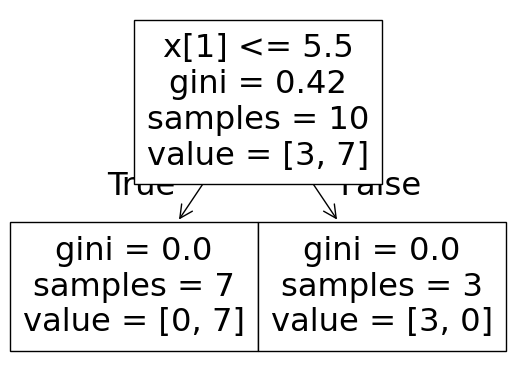

In [46]:
plot_tree(dt2)

<Axes: >

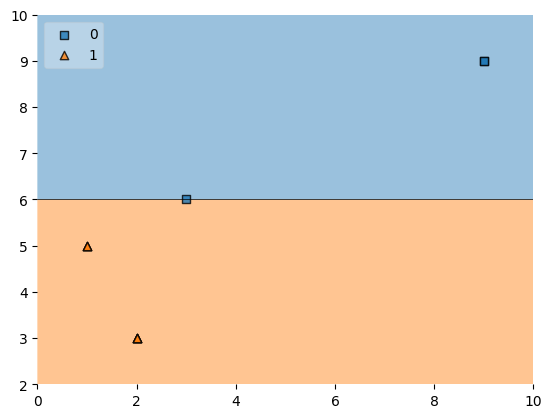

In [47]:
plot_decision_regions(X,y,clf=dt2, legend=2)

In [48]:
second_df['y_pred'] = dt2.predict(X)

In [49]:
second_df

,X1,X2,label,weights,y_pred
0,1,5,1,0.1,1
8,9,9,0,0.1,0
0,1,5,1,0.1,1
1,2,3,1,0.1,1
1,2,3,1,0.1,1
8,9,9,0,0.1,0
2,3,6,0,0.1,0
1,2,3,1,0.1,1
0,1,5,1,0.1,1
1,2,3,1,0.1,1


In [51]:
alpha2 = calculate_model_weight(0)

In [52]:
alpha2

8.05904782547916

In [53]:
second_df['updated_weights']=df.apply(update_row_weights,axis=1)

In [54]:
second_df

,X1,X2,label,weights,y_pred,updated_weights
0,1,5,1,0.1,1,0.152745
8,9,9,0,0.1,0,0.152745
0,1,5,1,0.1,1,0.152745
1,2,3,1,0.1,1,0.152745
1,2,3,1,0.1,1,0.152745
8,9,9,0,0.1,0,0.152745
2,3,6,0,0.1,0,0.152745
1,2,3,1,0.1,1,0.152745
0,1,5,1,0.1,1,0.152745
1,2,3,1,0.1,1,0.152745


In [55]:
second_df['normalized_weights'] = second_df['updated_weights']/second_df['updated_weights'].sum()

In [56]:
second_df

,X1,X2,label,weights,y_pred,updated_weights,normalized_weights
0,1,5,1,0.1,1,0.152745,0.1
8,9,9,0,0.1,0,0.152745,0.1
0,1,5,1,0.1,1,0.152745,0.1
1,2,3,1,0.1,1,0.152745,0.1
1,2,3,1,0.1,1,0.152745,0.1
8,9,9,0,0.1,0,0.152745,0.1
2,3,6,0,0.1,0,0.152745,0.1
1,2,3,1,0.1,1,0.152745,0.1
0,1,5,1,0.1,1,0.152745,0.1
1,2,3,1,0.1,1,0.152745,0.1
